<div dir="rtl">

### פרטי הסטודנטים
* **שם:** מתן
* **אות ראשונה של שם המשפחה:** א
* **4 ספרות אחרונות של ת"ז:** 5965
* **שם:** אופיר
* **אות ראשונה של שם המשפחה:** א
* **4 ספרות אחרונות של ת"ז:** 9461
</div>

<div dir="rtl">

### פרומפטים ב-AI LLM ועזרים נוספים
* **כלי ה-AI:** Gemini
* **פרומפטים:** "אני משתמש ב-fashion mnist מ-kaggle", "איך לסדר כתיבה בעברית במחברת", "מה לרשום על בעיית הלימוד".
* **מטרה:** סיוע בבניית שלד המחברת לפי דרישות המטלה, פתרון תקלות טכניות ב-Kernel וב-uv, וארגון המידע להגשה.

*עזרה בתכנון מבנה התפרויקט 
</div>

<div dir="rtl">

### הסבר על ה-Dataset ובעיית הלמידה
במטלה זו אנו מתמודדים עם בעיית **סיווג (Classification)** בתחום הראייה הממוחשבת. בחרנו להשתמש ב-**MNIST Dataset** מ-Kaggle.  הבעיה היא מסוג **למידה מונחית (Supervised Learning)**, כאשר המטרה היא לאמן מודל שיזהה 10 קטגוריות שונות של מוצרי אופנה (חולצות, מכנסיים, נעליים וכו׳) מתוך תמונות פיקסלים.  

</div>

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [13]:
train = pd.read_csv('fashion mnist/fashion-mnist_train.csv')
test = pd.read_csv('fashion mnist/fashion-mnist_test.csv')
print("First 5 rows of test set:\n")
display(test.head())
print("\nFirst 5 rows of train set:\n")
display(train.head())


First 5 rows of test set:



,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,9,8,...,103,87,56,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,34,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,14,53,99,...,0,0,0,0,63,53,31,0,0,0
3,2,0,0,0,0,0,0,0,0,0,...,137,126,140,0,133,224,222,56,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



First 5 rows of train set:



,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


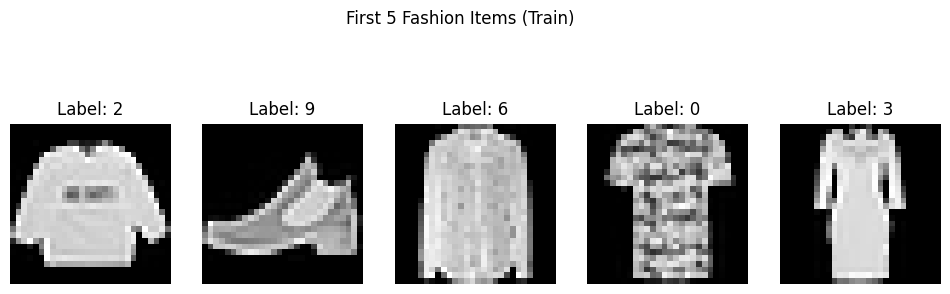

In [14]:
def show_first_five(df, title):
    plt.figure(figsize=(12, 4))
    for i in range(5):
        pixels = df.iloc[i, 1:].values.reshape(28, 28)
        label = df.iloc[i, 0]
        
        plt.subplot(1, 5, i + 1)
        plt.imshow(pixels, cmap='gray')
        plt.title(f"Label: {label}")
        plt.axis('off')
    plt.suptitle(title)
    plt.show()

show_first_five(train, "First 5 Fashion Items (Train)")

In [25]:
def calculate_manual_macro_f1(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    classes = np.unique(y_true)
    f1_scores = []

    for c in classes:
        tp = np.sum((y_true == c) & (y_pred == c))
        fp = np.sum((y_true != c) & (y_pred == c))
        fn = np.sum((y_true == c) & (y_pred != c))

        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0

        f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
        f1_scores.append(f1)

    macro_f1 = sum(f1_scores) / len(f1_scores)
    print(f"Manual Macro-Average F1 Score: {macro_f1:.4f}")
    return float(macro_f1)

# הרצה לבדיקה עם נתוני דמה
y_test_demo = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
y_pred_demo = [0, 1, 2, 0, 4, 5, 9, 7, 8, 9] 
calculate_manual_macro_f1(y_test_demo, y_pred_demo)

Manual Macro-Average F1 Score: 0.7333


0.7333333333333333